# Data lookup · duplicados e identidades antes de YOLO

**Objetivo:** limpiar el inventario e indexar candidatos para YOLO, conservando procedencia, etiquetas y motivos de exclusión.
**Pregunta:** ¿cuántas imágenes únicas tenemos y cuántas etiquetas comparten la misma imagen?
**Hipótesis comprobable:** elegir un representante por SHA-256 reduce entradas sin perder ningún hash distinto.

Fuentes: [Dogs of the World v1](https://www.kaggle.com/datasets/lextoumbourou/dogs-world) y
[LCW v1](https://www.kaggle.com/datasets/dseidli/lcwlabeled-cats-in-the-wild). La muestra es exactamente
la contenida en el CSV elegido; no se extrapolan sus cifras al 100% ni se inventan resultados.

Esta es preparación de datos: usa CPU, no llama a YOLO, CLIP, MLflow ni Hugging Face.
Exporta inventarios y un índice previo a YOLO; no borra fotos ni cambia las versiones usadas por E1/E2/E3.

## Fase 1. Preparación y preprocesamiento de datos

Ejecuta en una sesión **Colab CPU nueva**. La primera celda instala PetTrace 0.2.12 desde PyPI,
incluidos los gráficos. Colab ya proporciona IPython y los widgets.
CI valida la instalación normal contra el entorno reportado de Python 3.13.18.
Las salidas de la auditoría conservada corresponden al **50% con v0.2.11**, incluidos duplicados cercanos.
Para aplicar las ocho decisiones humanas a esa auditoría, ejecuta instalación/importaciones y la celda
«Aplicar revisión humana» de la fase 3; no repitas la fase 2. Si ya importaste PetTrace, reinicia
solo el kernel después de instalar; el reporte permanece en Drive.

Monta Drive y elige `SOURCE_SAMPLE_PCT`: 20, 50 o 100. El paquete recupera el **`review.csv` raw**
del respaldo confirmado de `MyDrive/PetTrace/checkpoints/preparation`, en una carpeta local separada.

Se leen los recibos y se copia/verifica únicamente el bloque TAR que contiene ese CSV; no se restauran
las imágenes, los ZIP ni los modelos. El CSV incluye los candidatos con etiqueta identificable antes
de YOLO, no el manifiesto refinado ni necesariamente todas las fotos del ZIP.
Si ese volumen no tiene inventario respaldado, se detiene: no usa otro porcentaje ni repite la preparación.
Los resultados quedan en `MyDrive/PetTrace/data-lookup`.

`CHECK_NEAR_COPIES = True` añade la búsqueda de copias redimensionadas/recomprimidas.
Ese paso sí necesita imágenes: recupera **un original por SHA-256 sin firma calculada** desde
el respaldo de preparación. No copia los ZIP ni ejecuta YOLO. La primera pasada implica leer
las imágenes únicas y puede tardar; no tiene el coste del análisis anterior de 30 segundos.
Las firmas se calculan en disco local y se respaldan en bloques incrementales en
`MyDrive/PetTrace/checkpoints/lookup-near`. Otra sesión recupera las firmas y solo calcula
las nuevas; no restaura las fotos ya firmadas. Una caída abrupta puede perder lo posterior
al último respaldo confirmado (intervalo de cinco minutos). Usa una sola sesión escritora.


In [1]:
%pip install -q --no-cache-dir "pettrace-ml==0.2.12"


In [2]:
from importlib.metadata import version
assert version("pettrace-ml") == "0.2.12", "Reejecuta la instalación antes de continuar."

import json
from pathlib import Path
from time import perf_counter
from IPython.display import FileLink, Markdown, display

from pettrace.data.lookup import lookup_duplicates, restore_lookup_review
from pettrace.data.review import quarantine_gallery, quarantine_groups


In [3]:
from google.colab import drive

WORK = Path("/content")
DRIVE_ROOT = WORK / "drive/MyDrive/PetTrace"
CHECK_NEAR_COPIES = True  # Copias de la misma foto; no reconocimiento del animal.
SOURCE_SAMPLE_PCT = 50  # Volumen que quieres auditar: 20, 50 o 100.
if not DRIVE_ROOT.parent.is_dir():
    drive.mount(str(WORK / "drive"))
OUTPUT_ROOT = DRIVE_ROOT / "data-lookup"

In [4]:
REVIEW_CSV = restore_lookup_review(DRIVE_ROOT, WORK, percent=SOURCE_SAMPLE_PCT)
print(f"Inventario raw del {SOURCE_SAMPLE_PCT}%:", REVIEW_CSV)
print("Reportes:", OUTPUT_ROOT)


Drive: buscando inventario raw del 50% en los recibos del respaldo…
Drive: 1 archivos verificados; respaldo listo.
Inventario raw del 50%: /content/data-lookup/restored/data/source-50-seed42/review.csv
Reportes: /content/drive/MyDrive/PetTrace/data-lookup


## Fase 2. Representación y entrenamiento

La representación usa **SHA-256** y, al activar la comparación visual, **dHash y miniaturas RGB**; no hay entrenamiento.
[SHA-256 está definido en FIPS 180-4](https://csrc.nist.gov/pubs/fips/180-4/upd1/final).
La política de limpieza es una decisión de esta investigación:

- Agrupar todas las filas por hash y escoger un representante de forma determinista.
- Conservar la relación de cada copia con su representante y todas las etiquetas de cada hash.
- Marcar las etiquetas contradictorias para revisión, sin escoger un animal como verdadero.
- Mantener los conteos raw completos y generar aparte `candidates.csv`: respetar `drop`, poner identidades contradictorias en cuarentena y conservar una copia por hash.
- Si se activa la comparación visual, revisar todos los hashes únicos antes del mínimo, incluso etiquetas pequeñas. Poner las etiquetas completas implicadas en posibles copias en cuarentena, también si las copias llevan la misma etiqueta.
- En el índice, exigir cuatro fotos distintas por etiqueta, igual que en la preparación actual. Las que no alcanzan quedan registradas; no se borran.
- `keep` tiene prioridad al elegir una copia. Una etiqueta pendiente puede ser candidata exploratoria, pero no se presenta como identidad validada.
- No resolver conflictos automáticamente ni ejecutar YOLO o asignar splits aquí.

`duplicados sobrantes = filas del inventario − hashes distintos`.
El paquete copia el CSV de entrada y registra sus hashes y los de sus salidas; una repetición idéntica
verifica y reutiliza el reporte. En modo SHA-256 no relee imágenes. La comparación visual verifica bytes nuevos y reutiliza firmas
por hash, versión del algoritmo y Pillow. La preparación vuelve a verificar las fotos al consumirlas.

[dHash (Neal Krawetz)](https://www.hackerfactor.com/blog/index.php?/archives/529-Kind-of-Like-That.html)
usa diferencias de brillo entre píxeles vecinos. Reutilizamos la representación de curación:
EXIF normalizado, dHash de 64 bits y RGB de 64×64. Los umbrales de esta investigación son
distancia Hamming ≤2, diferencia de aspecto <0,01 y MAE RGB ≤2 en escala 0–255.
Un índice de tres partes del hash propone comparaciones; se comprueban después los tres criterios.
Se conserva cada vínculo y sus puntuaciones. Una cadena A–B–C no garantiza parecido directo A–C
ni prueba identidad; no se fusionan etiquetas ni se eliminan fotos automáticamente.

In [5]:
started = perf_counter()
REPORT = lookup_duplicates(
    REVIEW_CSV, OUTPUT_ROOT, minimum_photos=4,
    near_cache=WORK / "data-lookup/signatures" if CHECK_NEAR_COPIES else None,
    drive_root=DRIVE_ROOT if CHECK_NEAR_COPIES else None,
)
summary = json.loads((REPORT / "summary.json").read_text())
print(f"Inventario analizado en {perf_counter() - started:.1f} s")
print("Reporte:", REPORT)

Drive: 0 archivos verificados; respaldo listo.
Copias cercanas: recuperando 325,380 originales sin firma; sin ZIP ni YOLO.
Drive: bloque restaurado (2233 archivos).
Drive: bloque restaurado (2212 archivos).
Drive: bloque restaurado (2167 archivos).
Drive: bloque restaurado (2150 archivos).
Drive: bloque restaurado (2134 archivos).
Drive: bloque restaurado (2071 archivos).
Drive: bloque restaurado (2045 archivos).
Drive: bloque restaurado (2104 archivos).
Drive: bloque restaurado (2106 archivos).
Drive: bloque restaurado (2060 archivos).
Drive: bloque restaurado (2017 archivos).
Drive: bloque restaurado (2020 archivos).
Drive: bloque restaurado (2037 archivos).
Drive: bloque restaurado (2004 archivos).
Drive: bloque restaurado (2060 archivos).
Drive: bloque restaurado (1996 archivos).
Drive: bloque restaurado (1986 archivos).
Drive: bloque restaurado (1974 archivos).
Drive: bloque restaurado (2014 archivos).
Drive: bloque restaurado (1968 archivos).
Drive: bloque restaurado (184 archivo

## Fase 3. Evaluación y análisis

Métricas: archivos, hashes únicos, copias sobrantes, porcentaje duplicado, etiquetas implicadas en
conflictos y fotos distintas por etiqueta. Una etiqueta de origen no equivale a un animal validado.
Los resultados siguientes se calculan al ejecutar este notebook.

In [6]:
print(f"Archivos: {summary['files']:,} → imágenes únicas: {summary['unique_images']:,}")
print(f"Copias exactas sobrantes: {summary['duplicate_copies']:,} ({summary['duplicate_pct']:.2f}%)")
print(f"Hashes con etiquetas contradictorias: {summary['conflicting_hashes']:,}")
print(f"Etiquetas involucradas: {summary['conflicting_identity_labels']:,}")
lines = ["| Fuente | Archivos | Hashes únicos | Copias dentro de la fuente |", "|---|---:|---:|---:|"]
for source, counts in summary["by_source"].items():
    lines.append(f"| {source} | {counts['files']:,} | {counts['unique_images']:,} | {counts['within_source_duplicate_copies']:,} |")
display(Markdown("\n".join(lines)))
print("Los conteos por fuente se calculan dentro de cada fuente; el global también cruza fuentes.")
print(f"Candidatas a YOLO: {summary['candidate_photos']:,} fotos / {summary['candidate_identities']:,} etiquetas")
print("Exclusiones previas:", summary["pre_yolo_exclusions"])
print(f"Candidatas sin aprobación manual: {summary['candidate_unverified_labels']:,}")

if "near_copy_pairs" in summary:
    print(f"Posibles copias cercanas: {summary['near_copy_pairs']:,} vínculos / {summary['near_copy_images']:,} imágenes")
    print(f"Etiquetas pendientes por parecido: {summary['near_copy_identity_labels']:,}")
    print(f"Imágenes únicas ilegibles: {summary['unreadable_unique_images']:,}")


Archivos: 347,296 → imágenes únicas: 325,380
Copias exactas sobrantes: 21,916 (6.31%)
Hashes con etiquetas contradictorias: 8,483
Etiquetas involucradas: 18,084


| Fuente | Archivos | Hashes únicos | Copias dentro de la fuente |
|---|---:|---:|---:|
| dogs-world | 156,835 | 139,404 | 17,431 |
| lcw | 190,461 | 185,976 | 4,485 |

Los conteos por fuente se calculan dentro de cada fuente; el global también cruza fuentes.
Candidatas a YOLO: 43,065 fotos / 10,067 etiquetas
Exclusiones previas: {'exact_duplicate': 1304, 'identity_review_pending': 36298, 'near_copy_review_pending': 2851, 'decode_error': 2, 'insufficient_distinct_photos': 263776}
Candidatas sin aprobación manual: 43,065
Posibles copias cercanas: 1,322 vínculos / 2,280 imágenes
Etiquetas pendientes por parecido: 2,514
Imágenes únicas ilegibles: 5


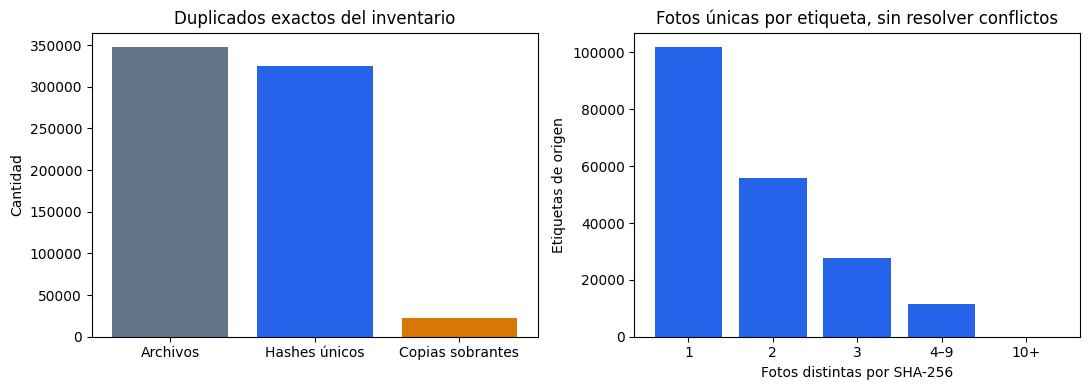

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(["Archivos", "Hashes únicos", "Copias sobrantes"],
            [summary["files"], summary["unique_images"], summary["duplicate_copies"]],
            color=["#64748b", "#2563eb", "#d97706"])
axes[0].set_title("Duplicados exactos del inventario")
axes[0].set_ylabel("Cantidad")
histogram = {int(n): count for n, count in summary["identities_by_distinct_photos"].items()}
bins = [sum(count for n, count in histogram.items() if low <= n <= high)
        for low, high in [(1, 1), (2, 2), (3, 3), (4, 9), (10, summary["files"])]]
axes[1].bar(["1", "2", "3", "4–9", "10+"], bins, color="#2563eb")
axes[1].set_title("Fotos únicas por etiqueta, sin resolver conflictos")
axes[1].set_xlabel("Fotos distintas por SHA-256")
axes[1].set_ylabel("Etiquetas de origen")
fig.tight_layout()
fig.savefig(REPORT.parent / f"{REPORT.name}-resumen.png", dpi=120)
plt.show()
plt.close(fig)

In [8]:
groups = quarantine_groups(REPORT)
print(f"Grupos de etiquetas conectadas para revisar: {len(groups):,}")
groups_file = REPORT.parent / f"{REPORT.name}-grupos.json"
groups_file.write_text(json.dumps({"lookup_fingerprint": REPORT.name, "decision": "pending", "groups": groups}, indent=2))
display(FileLink(str(groups_file)))

Grupos de etiquetas conectadas para revisar: 5,189


/content/drive/MyDrive/PetTrace/data-lookup/a7851270df2fbb656db064773cdbfee7d22dfb8d42c84031d4fb9f19a48056c6-grupos.json

### Revisión visual opcional

El conteo anterior no necesita las fotos. Esta celda solo muestra el visor si las imágenes originales
siguen disponibles en las rutas del CSV, por ejemplo en el mismo runtime de preparación. No las descarga
ni restaura. Cada imagen aparece una sola vez con sus etiquetas; las conexiones indirectas tampoco
prueban identidad. En una sesión nueva sin fotos, el visor se omite y el análisis del inventario queda completo.

Con comparación visual, el visor verifica un original disponible por hash y conserva las etiquetas
de sus copias según el inventario. Muestra los vínculos dHash/MAE junto a los grupos de cuarentena.
Una sesión que solo recuperó firmas puede necesitar los originales para mostrar el visor.


In [9]:
BATCH_START = 0  # 0, 8, 16…
if groups:
    try:
        gallery = quarantine_gallery(REPORT, REPORT.parent / f"{REPORT.name}-grupos-{BATCH_START:04d}.html",
                                     start=BATCH_START, count=8, representatives_only=CHECK_NEAR_COPIES)
    except FileNotFoundError:
        print("Visor omitido: faltan fotos originales en sus rutas. El análisis del inventario está completo.")
    else:
        display(FileLink(str(gallery)))
else:
    print("No hay conflictos de etiquetas por hash en este inventario.")

/content/drive/MyDrive/PetTrace/data-lookup/a7851270df2fbb656db064773cdbfee7d22dfb8d42c84031d4fb9f19a48056c6-grupos-0000.html

### Salidas y límites

`unique-images.csv` contiene un representante por hash con **todas** sus etiquetas;
`duplicate-copies.csv` relaciona las copias con ese representante. `review.csv` conserva la entrada exacta,
`candidates.csv` lista las fotos elegibles para el siguiente paso; `excluded.csv` explica cada exclusión.
`audit.json` conserva los conflictos y `lookup.json` la procedencia e integridad del reporte.

La auditoría automática no elimina fotos ni resuelve identidades. El resultado **no es un dataset listo para entrenar**:
aún requiere revisar identidades pendientes, verificar bytes, aplicar YOLO y deduplicación cercana, proteger el benchmark y asignar splits.
El mínimo puede dejar de cumplirse tras esos controles. Este índice no garantiza que todas sus fotos entrenen.
El modo SHA-256 no detecta recomprimidos. La comparación visual propone copias muy cercanas, pero puede omitir recompresiones fuertes, recortes, giros o ediciones. No identifica animales entre fotos distintas ni garantiza ausencia de duplicados.
La celda de revisión siguiente aplica únicamente confirmaciones explícitas, en otro índice.
La modificación física de una foto posterior al inventario no se detecta hasta volver a verificar sus bytes.
Cambiar la limpieza para futuros experimentos requiere una versión nueva; no altera las corridas históricas.

### Usar el índice en la preparación siguiente

En `prepare_training`, pasa la ruta completa que imprime `REPORT` como `candidate_index`,
y una **versión nueva**, por ejemplo `v3.100` (o el porcentaje auditado):

```python
from pettrace.data.workflow import TrainingPreparation

preparation = TrainingPreparation(
    drive_root=DRIVE_ROOT, work_dir="/content",
    source_percent=SOURCE_SAMPLE_PCT, screening_provider="cuda",
    candidate_index=REPORT, version=f"v3.{SOURCE_SAMPLE_PCT}",
)
```

Esto configura el siguiente trabajo; aquí no se ejecuta. `prepare()` comprueba que el índice
coincida con el inventario y sus decisiones antes de YOLO, protege val/test v1 y guarda su procedencia.
Si cambia el CSV, hay que regenerar el índice. Las imágenes siguen recuperándose en la preparación;
este paso solo reduce las fotos enviadas a YOLO. Los experimentos cargarán la versión refinada resultante.


In [10]:
for filename in ("summary.json", "candidates.csv", "excluded.csv", "unique-images.csv", "duplicate-copies.csv", "audit.json", "lookup.json"):
    display(FileLink(str(REPORT / filename)))


/content/drive/MyDrive/PetTrace/data-lookup/a7851270df2fbb656db064773cdbfee7d22dfb8d42c84031d4fb9f19a48056c6/summary.json

/content/drive/MyDrive/PetTrace/data-lookup/a7851270df2fbb656db064773cdbfee7d22dfb8d42c84031d4fb9f19a48056c6/candidates.csv

/content/drive/MyDrive/PetTrace/data-lookup/a7851270df2fbb656db064773cdbfee7d22dfb8d42c84031d4fb9f19a48056c6/excluded.csv

/content/drive/MyDrive/PetTrace/data-lookup/a7851270df2fbb656db064773cdbfee7d22dfb8d42c84031d4fb9f19a48056c6/unique-images.csv

/content/drive/MyDrive/PetTrace/data-lookup/a7851270df2fbb656db064773cdbfee7d22dfb8d42c84031d4fb9f19a48056c6/duplicate-copies.csv

/content/drive/MyDrive/PetTrace/data-lookup/a7851270df2fbb656db064773cdbfee7d22dfb8d42c84031d4fb9f19a48056c6/audit.json

/content/drive/MyDrive/PetTrace/data-lookup/a7851270df2fbb656db064773cdbfee7d22dfb8d42c84031d4fb9f19a48056c6/lookup.json

### Aplicar revisión humana · grupos 1–8

Alessandro confirmó visualmente un animal por grupo, incluidos los grupos 2 y 3. El registro
fija las etiquetas, hashes y conteos de la galería original. Se crean alias y un **índice nuevo**;
`review.csv` y los reportes anteriores permanecen intactos. No se releen fotos ni se ejecuta YOLO.
Los grupos 2 y 8 tienen solo 2 y 3 hashes distintos: siguen fuera por el mínimo de cuatro.
Las copias cercanas y los demás grupos continúan pendientes; confirmar identidad no aprueba calidad.

Esta celda usa el reporte original guardado en Drive. Para seguir revisando, muestra los grupos
9–16 de ese mismo reporte (`BATCH_START = 8`), conservando su numeración.
Para preparar datos después, usa `REVIEWED_REPORT` como `candidate_index` y una versión nueva.


In [ ]:
from hashlib import sha256
from urllib.request import urlretrieve

BASE_REPORT = Path("/content/drive/MyDrive/PetTrace/data-lookup/a7851270df2fbb656db064773cdbfee7d22dfb8d42c84031d4fb9f19a48056c6")
DECISIONS = Path("/content/a7851270df2fbb656db064773cdbfee7d22dfb8d42c84031d4fb9f19a48056c6-groups-0001-0008.json")
urlretrieve("https://raw.githubusercontent.com/alessandro54/pettrace-ml/v0.2.12/datasets/reviews/a7851270df2fbb656db064773cdbfee7d22dfb8d42c84031d4fb9f19a48056c6-groups-0001-0008.json", DECISIONS)
assert sha256(DECISIONS.read_bytes()).hexdigest() == "7d47bdbfc168351babefb2cb6af622c3dfbe9477df66d077c92bde249899df1f", "El registro de revisión cambió"
REVIEWED_REPORT = lookup_duplicates(BASE_REPORT / "review.csv", BASE_REPORT.parent, identity_review=DECISIONS)
before = json.loads((BASE_REPORT / "summary.json").read_text())
after = json.loads((REVIEWED_REPORT / "summary.json").read_text())
print(f"Revisión aplicada: {after['reviewed_original_labels']} etiquetas → {after['reviewed_identity_groups']} identidades confirmadas")
print(f"Candidatas a YOLO: {before['candidate_photos']:,} → {after['candidate_photos']:,} fotos; {before['candidate_identities']:,} → {after['candidate_identities']:,} etiquetas")
print("Índice nuevo:", REVIEWED_REPORT)
display(FileLink(str(REVIEWED_REPORT / "identity-review.json")))
